# Agrupamento de condomínios com K-Means

Os condomínios de uma rota operacional precisam ser divididos em **6 núcleos**. O critério é a proximidade geográfica, e os núcleos devem ter volume parecido: não cabe um grupo com poucos prédios e outro com dezenas.

O K-Means clássico minimiza a distância ao centro do grupo, mas não controla quantos pontos cada grupo recebe. Este estudo ajusta o K-Means e, em seguida, limita as vagas de cada núcleo.

## 1. Dados

Cada condomínio entra no modelo por duas variáveis: latitude e longitude, obtidas a partir do nome, do endereço, do bairro e da cidade.

In [1]:
import pandas as pd
from openpyxl import load_workbook

from project_clustering_kmeans.clustering import assign_nuclei
from project_clustering_kmeans.data import coordinates_from_sheet, read_rows
from project_clustering_kmeans.settings import N_CLUSTERS, NUCLEUS_COLORS, WORKBOOK_PATH

worksheet = load_workbook(WORKBOOK_PATH).active
rows = read_rows(worksheet)
located = coordinates_from_sheet(worksheet, rows)

condominios = pd.DataFrame(rows)
condominios["latitude"] = condominios["ordem"].map(lambda ordem: located[ordem]["lat"])
condominios["longitude"] = condominios["ordem"].map(lambda ordem: located[ordem]["lon"])

print(f"{len(condominios)} condomínios com coordenada")
condominios[["nome", "bairro", "cidade", "latitude", "longitude"]].head()

134 condomínios com coordenada


,nome,bairro,cidade,latitude,longitude
0,Condomínio do Edifício Waves,Ponta Verde,Maceió/AL,-9.658611,-35.709002
1,CONDOMINIO DO EDIFICIO DOM JUAN DIAZ DE SOLIS,Ponta Verde,Maceió/AL,-9.663488,-35.705864
2,Condomínio do Edifício Alto Mar,Ponta Verde,Maceió/AL,-9.663238,-35.705018
3,Edificio Residencial Perola Mar,Ponta Verde,Maceió/AL,-9.661411,-35.708378
4,Condomínio Anthony Leahy,Ponta Verde,Maceió/AL,-9.661452,-35.704441


## 2. Espaço de atributos

Latitude e longitude em graus não formam um plano em que a distância euclidiana seja a distância no mapa. Antes do K-Means, as coordenadas são projetadas para metros em torno do centro da amostra. Um grau de latitude vale cerca de 110,5 km; um grau de longitude é corrigido pelo cosseno da latitude média.

## 3. Modelo

O número de núcleos é fixo: **k = 6**, porque a rota operacional é dividida em seis frentes.

1. `KMeans(n_clusters=6, n_init=20, random_state=42)` estima os centros.
2. Cada condomínio é atribuído ao centro mais próximo, com capacidade limitada. Com 134 prédios, quatro núcleos recebem 22 e dois recebem 23.
3. Os centros são recalculados e a atribuição se repete até estabilizar.
4. Os rótulos são renumerados pela latitude do centroide, de sul para norte.

A semente `random_state=42` torna o ajuste reproduzível.

In [2]:
nuclei = assign_nuclei(rows, located)
condominios["nucleo"] = condominios["ordem"].map(nuclei)
condominios["cor"] = condominios["nucleo"].map(
    lambda nucleo: NUCLEUS_COLORS[nucleo - 1][0]
)

resumo = (
    condominios.groupby(["nucleo", "cor"], as_index=False)
    .agg(condominios=("ordem", "size"), bairros=("bairro", lambda values: ", ".join(sorted(set(values)))))
    .sort_values("nucleo")
)
print(f"k = {N_CLUSTERS}")
resumo

k = 6


,nucleo,cor,condominios,bairros
0,1,Vermelho,22,"Centro, Farol, Francês, Jatiúca, Litorânea, Pa..."
1,2,Laranja,23,Ponta Verde
2,3,Amarelo,22,Ponta Verde
3,4,Verde,23,"Jatiúca, Ponta Verde"
4,5,Azul,22,"Gruta de Lourdes, Jacintinho, Jatiúca, Mangabe..."
5,6,Roxo,22,"Cruz das Almas, Guaxuma, Jatiúca, Ponta Verde"


## 4. Resultado

Os seis núcleos cobrem a rota de sul para norte. O núcleo 1 reúne o trecho mais ao sul, onde há poucos prédios, e por isso ocupa uma área maior para chegar ao mesmo volume dos núcleos da orla, que são mais densos.

O gráfico abaixo usa a mesma projeção do modelo. O mapa com as ruas está em `images/nucleos_mapa.html`.

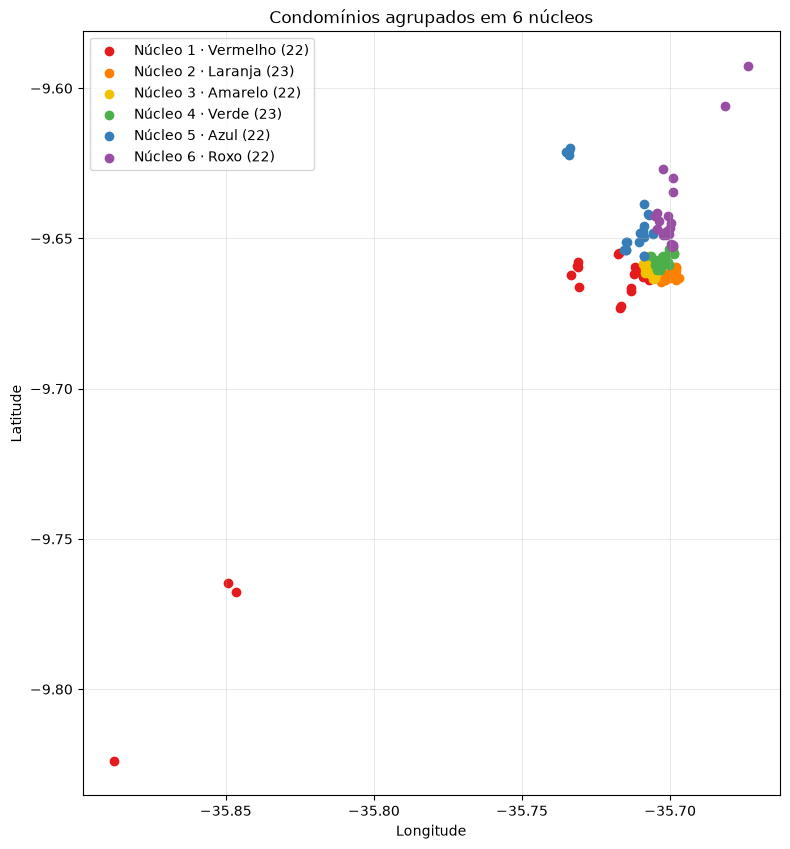

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 10))
for nucleus, (color_name, color_hex) in enumerate(NUCLEUS_COLORS, start=1):
    part = condominios[condominios["nucleo"] == nucleus]
    ax.scatter(
        part["longitude"],
        part["latitude"],
        c=f"#{color_hex}",
        s=36,
        label=f"Núcleo {nucleus} · {color_name} ({len(part)})",
    )
ax.set_title("Condomínios agrupados em 6 núcleos")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.deg2rad(condominios["latitude"].mean())))
ax.grid(True, linewidth=0.4, alpha=0.5)
ax.legend(loc="upper left", frameon=True)
fig.tight_layout()